### Kool – Lösung Schritt für Schritt

*30. Bundeswettbewerb Informatik (2011/2012), 2. Runde, Aufgabe 2*

Im Kindergarten „Die Schlaumäuse“ befindet sich in einer Ecke die Kinder-Ortungs-und-Orientierungs-Lernhilfe. Kool besteht aus
leichten versetzbaren Würfeln, die zusammen ein für Kinder begehbares Labyrinth bilden können. Die Würfel sind Geradeaus-Gänge,
Knicke, T-Kreuzungen, (Vierwege-)Kreuzungen und Sackgassen. Jeder Würfel ist außerdem an einer Seite farblich markiert. Das folgende
Bild zeigt die unterschiedlichen Arten von Würfeln.

*(Bild im Aufgabenblatt: die 15 Würfel von oben, die Farbmarkierung jeweils an der oberen Seite. Mit Kastenzeichen, bei denen jeder
Strich zu einer offenen Seite führt: Geradeaus-Gänge `─ │`, Knicke `┐ └ ┌ ┘`, T-Kreuzungen `┤ ┴ ├ ┬`, Kreuzung `┼`,
Sackgassen `╴ ╵ ╶ ╷`.)*

Jeden Monat bauen die Mitarbeiter des Kindergartens ein neues Labyrinth aus den vorhandenen Würfeln. Das macht ihnen aber doch
einiges an Kopfzerbrechen, denn in einem Kool-Labyrinth sollen erstens natürlich alle Labyrinthgänge tatsächlich vom Eingang aus
erreichbar sein, und zweitens soll eine Sackgasse nicht einfach dadurch entstehen, dass der nächste Würfel auf der betreffenden Seite
keinen Eingang hat, sondern nur mit Hilfe der Sackgassenwürfel. Für den Raumbedarf des Kindergartens ist außerdem wichtig, dass ein
Kool-Labyrinth möglichst kompakt gebaut wird; die Würfel sollen auf einer möglichst kleinen Rechteckfläche aufgebaut werden. Zu
Ortungs-und-Orientierungs-Lernzwecken müssen schließlich zwei weitere Bedingungen erfüllt werden: Zum einen muss die Farbmarkierung
in einem fertigen Labyrinth bei allen Würfeln in die gleiche Richtung zeigen. Zum anderen darf ein Labyrinth nur einen Eingang
haben; in dem das Labyrinth genau umfassenden Rechteck muss er sich in der der Raumecke gegenüberliegenden Ecke befinden.

Das folgende Bild zeigt ein Kool-Labyrinth. Die starken Linien sind Wände, die gestrichelte Linie zeigt das Rechteck, dass das
Labyrinth genau umfasst. Der einzige Eingang befindet sich oben links, gegenüber der Raumecke.

*(Bild im Aufgabenblatt: ein Labyrinth aus 26 Würfeln in einem Rechteck von 5 Reihen und 6 Spalten, die Raumecke rechts unten, alle
Farbmarkierungen oben. Abgelesen, mit · für ein freies Feld:)*

```
──┬─┐·
·╷├┬┘·
┌┘└┼┬┐
├┐┌┘││
└┴┘·└┘
```

#### Aufgabe

Schreibe ein Programm, das den Mitarbeitern hilft, Kool-Labyrinthe aufzubauen. Dein Programm soll für eine gegebene Menge von Würfeln
Kool-Labyrinthe ermitteln und ausgeben, die sich aus den Würfeln bauen lassen. Es soll allgemein genug sein, um anderen
Kindergärtnern in einer ähnlichen Situation (aber mit anderen, potenziell deutlich größeren Würfelmengen) auch helfen zu können.
Teste dein Programm mit der im obigen Beispiellabyrinth benutzten Würfelmenge und mit weiteren interessanten Beispielen.

#### Beispieldaten

Laut BWINF-Archiv gibt es zu dieser Aufgabe keine Beispieldaten. Wir haben die Würfelmengen deshalb selbst in Dateien geschrieben.
Das Format ist unsere Wahl: Jedes Kastenzeichen ist ein Würfel, die Striche zeigen zu den offenen Seiten (`─` links und rechts,
`┌` rechts und unten, `╴` nur links usw.). Leerzeichen und `·` zählen nicht, Zeilen mit `#` am Anfang sind Kommentare. Wie die
Würfel in der Datei angeordnet sind, spielt keine Rolle – es zählt nur, wie viele es von jeder Sorte gibt.

In `beispieldaten/`: `aufgabe.txt` mit den 26 Würfeln aus dem Beispiellabyrinth, so angeordnet wie im Bild.

In `eigene_testdaten/`: `ein_wuerfel.txt` (nur eine Sackgasse), `kamm.txt` (ein Gang mit vier Sackgassen), `gitter.txt` (volles
Gitter aus 3 × 3 Würfeln), `kein_eingang.txt` (ein geschlossener Ring), `unmoeglich.txt` (drei Sackgassen, die nicht zusammenpassen)
und zwei große zufällige Würfelmengen `zufall_8x8.txt` (64 Würfel) und `zufall_10x10.txt` (92 Würfel), die wir weiter unten erzeugen.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Tiefensuche mit Zurücknehmen (Backtracking):** Würfel für Würfel anlegen und zurücknehmen, wenn es nicht weitergeht – wie beim
  Puzzeln. Die Lösungshinweise schlagen vor, vom Eingang aus immer nur an das schon gebaute Labyrinth anzulegen.
- **Abbruchkriterien (Pruning):** früh erkennen, dass ein halb gebautes Labyrinth nicht mehr fertig werden kann.
- **Tiefensuche auf einem Gitter:** Welche Felder erreicht man vom Eingang aus durch die Gänge? So prüfen wir den Zusammenhang.
- **Zufall und Neustarts:** Eine Suche, die sich verrannt hat, mit einer anderen zufälligen Reihenfolge neu beginnen.
- **Simulierte Abkühlung (Simulated Annealing):** ein heuristisches Verfahren, das die Lösungshinweise für große Würfelmengen
  empfehlen. Alle Würfel liegen von Anfang an auf dem Brett, und wir tauschen so lange, bis keine Fehler mehr übrig sind.

**Nützliche Funktionen und Bibliotheken**
- Ein Würfel ist bei uns ein String aus den Buchstaben seiner offenen Seiten, z. B. `'LRU'`; `'U' in w` prüft, ob er unten offen ist.
- Dictionarys: der Vorrat als `{Würfel: Anzahl}`, `vorrat.get(w, 0)` für Sorten, die nicht vorkommen.
- Unicode-Kastenzeichen (`─ │ ┌ ┐ └ ┘ ├ ┤ ┬ ┴ ┼ ╴ ╶ ╵ ╷`) für eine übersichtliche Ausgabe in Textform.
- `random.Random(zahl)`: ein Zufallsgenerator mit festem Startwert, damit die Ausgaben bei jedem Lauf gleich sind;
  `shuffle` mischt eine Liste, `sample(liste, 2)` wählt zwei verschiedene Elemente.
- `math.log` für die Abkühlung, `matplotlib` zum Zeichnen der Labyrinthe.

## Die Idee in Worten

**Das Modell.** Weil die Farbmarkierung bei allen Würfeln in dieselbe Richtung zeigen muss, darf man keinen Würfel drehen. Es gibt
also nicht fünf, sondern 15 **Sorten** von Würfeln, je nachdem, welche der vier Seiten links (L), rechts (R), oben (O) und unten
(U) offen sind (die Lösungshinweise nennen die offenen Seiten **Kontakte**). Die Würfel liegen auf einem rechteckigen **Brett** aus
m Zeilen und n Spalten. Das Eingangsfeld ist das Feld links oben (Zeile 0, Spalte 0).

**Die Bedingungen** für ein Kool-Labyrinth:
1. Alle Würfel des Vorrats werden verbaut (sonst wäre ein einzelner Würfel immer das kleinste „Labyrinth“).
2. An jeder Kante zwischen zwei Feldern haben entweder beide Seiten einen Kontakt oder keine. Eine Sackgasse entsteht so nur durch
   einen Sackgassenwürfel. Ein freies Feld hat keine Kontakte.
3. Kein Kontakt zeigt aus dem Brett hinaus, außer genau einem: dem Eingang am Feld links oben (nach links oder nach oben).
4. Jeder Würfel ist vom Eingang aus erreichbar.
5. Das Rechteck umfasst das Labyrinth genau: In der letzten Zeile und in der letzten Spalte liegt mindestens ein Würfel. (Erste Zeile
   und erste Spalte sind wegen des Eingangs ohnehin belegt.)

**Vorher zählen.** Jeder Kontakt nach rechts gehört zu einem Kontakt nach links beim Nachbarn. Also muss es genauso viele L- wie
R-Kontakte geben, nur der Eingang hat keinen Partner. Daran sieht man schon vor jeder Suche, ob der Eingang nach links oder nach oben
zeigt – oder ob es gar kein Labyrinth geben kann.

**Die Suche.** Wir probieren Brettgrößen der Reihe nach, die kleinste Fläche zuerst. Für jede Größe bauen wir das Labyrinth wie in den
Lösungshinweisen vom Eingang aus auf: Ein **offenes Feld** ist ein freies Feld, auf das ein Kontakt eines schon gelegten Würfels
zeigt. Es muss belegt werden, und zwar mit einem Würfel, der zu allen Nachbarn und zum Rand passt. Wir nehmen immer das offene Feld,
für das die wenigsten Würfel passen, und probieren diese der Reihe nach (Tiefensuche). Gibt es keine offenen Felder mehr, ist das
Labyrinth geschlossen; sind dann alle Würfel verbaut, haben wir eine Lösung. Der Zusammenhang ist automatisch erfüllt, weil wir nur
an das schon gebaute Labyrinth anlegen.

**Große Würfelmengen.** Für 26 Würfel ist die Tiefensuche schnell, für 60 oder 100 Würfel verrennt sie sich. Dann helfen Neustarts
mit zufälliger Reihenfolge und – wie in den Lösungshinweisen – die simulierte Abkühlung.

## Schritt 1: Würfel und Brett darstellen

Ein Würfel ist ein String aus den Buchstaben seiner Kontakte, immer in der Reihenfolge L, R, O, U. `'LRU'` ist also die T-Kreuzung,
die links, rechts und unten offen ist. Ein freies Feld ist der leere String `''`. Das Brett ist eine Liste von Zeilen, jede Zeile eine
Liste von Würfeln; `brett[r][c]` ist das Feld in Zeile `r` und Spalte `c` (beide ab 0 gezählt, Zeile 0 ist oben).

`SCHRITT` sagt, wie sich Zeile und Spalte ändern, wenn man durch eine Seite hinausgeht, `GEGEN` nennt die gegenüberliegende Seite:
Ein Kontakt nach rechts (R) trifft beim rechten Nachbarn auf dessen linke Seite (L). `zeige` gibt ein Brett mit Kastenzeichen aus.

In [ ]:
import math
import random
import matplotlib.pyplot as plt

SCHRITT = {'L': (0, -1), 'R': (0, 1), 'O': (-1, 0), 'U': (1, 0)}     # so ändern sich (Zeile, Spalte)
GEGEN = {'L': 'R', 'R': 'L', 'O': 'U', 'U': 'O'}                     # die gegenüberliegende Seite
ZEICHEN = {'LR': '─', 'OU': '│',                                     # Geradeaus-Gänge
           'LU': '┐', 'RO': '└', 'RU': '┌', 'LO': '┘',               # Knicke
           'LOU': '┤', 'LRO': '┴', 'ROU': '├', 'LRU': '┬',           # T-Kreuzungen
           'LROU': '┼',                                              # Kreuzung
           'L': '╴', 'O': '╵', 'R': '╶', 'U': '╷'}                   # Sackgassen
WUERFEL = {}                                                         # umgekehrt: Zeichen -> Würfel
for w in ZEICHEN:
    WUERFEL[ZEICHEN[w]] = w
LEER = '·'


def zeige(brett):
    """Das Brett als Text mit Kastenzeichen, · für ein freies Feld."""
    zeilen = []
    for zeile in brett:
        text = ''
        for w in zeile:
            if w == '':
                text += LEER
            else:
                text += ZEICHEN[w]
        zeilen.append(text)
    return '\n'.join(zeilen)


for w in ZEICHEN:
    print(f'{ZEICHEN[w]}  {w}')

─  LR
│  OU
┐  LU
└  RO
┌  RU
┘  LO
┤  LOU
┴  LRO
├  ROU
┬  LRU
┼  LROU
╴  L
╵  O
╶  R
╷  U


Mit `matplotlib` zeichnen wir ein Brett so ähnlich wie im Aufgabenblatt: Würfel grau, Gänge gelb, freie Felder weiß. Die blaue
Farbmarkierung lassen wir weg, sie ist ja bei allen Würfeln oben.

In [ ]:
def zeichne(brett, ax, titel=''):
    m, n = len(brett), len(brett[0])
    for r in range(m):
        for c in range(n):
            w = brett[r][c]
            if w == '':
                continue
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor='#aaaaaa', edgecolor='black', linewidth=0.5))
            mx, my = c + 0.5, r + 0.5                       # Mitte des Feldes (y nach unten, siehe invert_yaxis)
            ax.add_patch(plt.Rectangle((mx - 0.17, my - 0.17), 0.34, 0.34, facecolor='#fff47a', edgecolor='none'))
            for d in w:                                     # ein gelber Gang von der Mitte zu jeder offenen Seite
                dr, dc = SCHRITT[d]
                x0, x1 = sorted([mx, mx + 0.5 * dc])
                y0, y1 = sorted([my, my + 0.5 * dr])
                ax.add_patch(plt.Rectangle((x0 - 0.17 * (dc == 0), y0 - 0.17 * (dr == 0)),
                                           x1 - x0 + 0.34 * (dc == 0), y1 - y0 + 0.34 * (dr == 0),
                                           facecolor='#fff47a', edgecolor='none'))
    ax.plot([0, n, n, 0, 0], [0, 0, m, m, 0], 'k--', linewidth=0.8)   # das umfassende Rechteck
    ax.set_xlim(-0.2, n + 0.2)
    ax.set_ylim(-0.2, m + 0.2)
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(titel)

## Schritt 2: Würfelmengen und Bretter einlesen

`lies_vorrat` zählt die Kastenzeichen einer Datei: Das Ergebnis ist ein Dictionary `{Würfel: Anzahl}`. `lies_brett` liest dieselbe
Datei als Brett (jede Textzeile eine Zeile des Bretts); das brauchen wir nur für das Labyrinth aus dem Aufgabenblatt, um unsere
Prüfung daran zu testen. `vorrat_von` zählt die Würfel auf einem Brett.

─ 3  │ 2  ┐ 3  └ 3  ┌ 2  ┘ 5  ┴ 1  ├ 2  ┬ 3  ┼ 1  ╷ 1  (26 Würfel)
──┬─┐·
·╷├┬┘·
┌┘└┼┬┐
├┐┌┘││
└┴┘·└┘


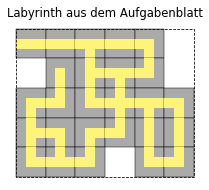

In [ ]:
def lies_zeilen(dateiname):
    zeilen = []
    with open(dateiname, encoding='utf-8') as datei:
        for zeile in datei:
            zeile = zeile.rstrip('\n')
            if not zeile.startswith('#') and zeile.strip() != '':
                zeilen.append(zeile)
    return zeilen


def lies_vorrat(dateiname):
    vorrat = {}
    for zeile in lies_zeilen(dateiname):
        for zeichen in zeile:
            if zeichen in WUERFEL:
                w = WUERFEL[zeichen]
                vorrat[w] = vorrat.get(w, 0) + 1
            elif zeichen not in ' ' + LEER:
                raise ValueError(f'Unbekanntes Zeichen {zeichen!r} in {dateiname}')
    return vorrat


def lies_brett(dateiname):
    zeilen = lies_zeilen(dateiname)
    n = max(len(zeile) for zeile in zeilen)
    brett = []
    for zeile in zeilen:
        reihe = []
        for zeichen in zeile.ljust(n):               # kürzere Zeilen rechts mit Leerzeichen auffüllen
            reihe.append(WUERFEL.get(zeichen, ''))
        brett.append(reihe)
    return brett


def vorrat_von(brett):
    vorrat = {}
    for zeile in brett:
        for w in zeile:
            if w != '':
                vorrat[w] = vorrat.get(w, 0) + 1
    return vorrat


def als_text(vorrat):
    """Der Vorrat kurz als Text, z. B. '─ 3  ┐ 3 ... (26 Würfel)'."""
    teile = []
    for w in ZEICHEN:                                # in der festen Reihenfolge der Sorten
        if vorrat.get(w, 0) > 0:
            teile.append(f'{ZEICHEN[w]} {vorrat[w]}')
    return '  '.join(teile) + f'  ({sum(vorrat.values())} Würfel)'


AUFGABE = lies_vorrat('beispieldaten/aufgabe.txt')
BILD = lies_brett('beispieldaten/aufgabe.txt')
print(als_text(AUFGABE))
print(zeige(BILD))
fig, ax = plt.subplots(figsize=(3.5, 3))
zeichne(BILD, ax, 'Labyrinth aus dem Aufgabenblatt')
plt.show()

Unter den 26 Würfeln sind nur eine einzige Sackgasse (`╷`) und eine Kreuzung (`┼`), aber 13 Knicke.

## Schritt 3: Ein Labyrinth prüfen

Bevor wir suchen, schreiben wir eine Prüfung, die jedes gefundene Labyrinth unabhängig von der Suche nachrechnet.

`kontakt(brett, r, c, d, eingang)` sagt, ob das Feld (r, c) an der Seite d offen ist. Das Feld darf auch außerhalb des Bretts liegen:
Dort ist alles geschlossen, mit einer Ausnahme – das Feld links neben (0, 0) bzw. über (0, 0) tut so, als hätte es einen Kontakt zum
Eingang hin. So wird der Eingang wie ein ganz normaler Nachbar behandelt.

`falsche_kanten` geht alle Kanten durch, die ein Feld des Bretts berühren, und sammelt die, bei denen nur eine Seite offen ist. Eine
Kante bezeichnen wir durch das Feld links bzw. oberhalb davon und die Richtung `'R'` (Kante rechts davon) oder `'U'` (Kante darunter).

In [ ]:
def kontakt(brett, r, c, d, eingang):
    """Ist das Feld (r, c) an der Seite d offen? Außerhalb des Bretts gibt es nur den Eingang."""
    m, n = len(brett), len(brett[0])
    if 0 <= r < m and 0 <= c < n:
        return d in brett[r][c]
    if eingang == 'L' and (r, c, d) == (0, -1, 'R'):      # links neben dem Eingangsfeld
        return True
    if eingang == 'O' and (r, c, d) == (-1, 0, 'U'):      # über dem Eingangsfeld
        return True
    return False


def falsche_kanten(brett, eingang):
    m, n = len(brett), len(brett[0])
    falsch = []
    for r in range(-1, m):
        for c in range(-1, n):
            for d in 'RU':
                r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]       # das Feld auf der anderen Seite der Kante
                innen1 = 0 <= r < m and 0 <= c < n
                innen2 = 0 <= r2 < m and 0 <= c2 < n
                if innen1 or innen2:
                    if kontakt(brett, r, c, d, eingang) != kontakt(brett, r2, c2, GEGEN[d], eingang):
                        falsch.append((r, c, d))
    return falsch


def erreichbar(brett):
    """Alle Felder, die man vom Eingangsfeld (0, 0) aus durch die Gänge erreicht (Tiefensuche)."""
    m, n = len(brett), len(brett[0])
    if brett[0][0] == '':
        return set()
    gesehen = {(0, 0)}
    stapel = [(0, 0)]
    while stapel:
        r, c = stapel.pop()
        for d in brett[r][c]:
            r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
            if 0 <= r2 < m and 0 <= c2 < n and GEGEN[d] in brett[r2][c2] and (r2, c2) not in gesehen:
                gesehen.add((r2, c2))
                stapel.append((r2, c2))
    return gesehen

Welche Seite ist der Eingang? Das sagt uns die Zählung aus der Idee: Jeder Kontakt nach rechts hat einen Partner nach links und
umgekehrt, nur der Eingang nicht. Gibt es einen L-Kontakt mehr als R-Kontakte (und gleich viele O- und U-Kontakte), zeigt der Eingang
nach links. Gibt es einen O-Kontakt mehr, zeigt er nach oben. In allen anderen Fällen kann man aus diesen Würfeln kein Labyrinth mit
Eingang links oben bauen. `eingang_von` gibt `'L'`, `'O'` oder `None` zurück.

Damit kann `pruefe` alle fünf Bedingungen nachrechnen und gibt eine Liste von Fehlern zurück (leer = gültig).

In [ ]:
def zaehle_kontakte(vorrat):
    anzahl = {'L': 0, 'R': 0, 'O': 0, 'U': 0}
    for w in vorrat:
        for d in w:
            anzahl[d] += vorrat[w]
    return anzahl


def eingang_von(vorrat):
    a = zaehle_kontakte(vorrat)
    if a['L'] == a['R'] + 1 and a['O'] == a['U']:
        return 'L'
    if a['O'] == a['U'] + 1 and a['L'] == a['R']:
        return 'O'
    return None


def rechteck_genau(brett):
    """Liegt in der letzten Zeile und in der letzten Spalte mindestens ein Würfel?"""
    unten = False
    for w in brett[-1]:
        if w != '':
            unten = True
    rechts = False
    for zeile in brett:
        if zeile[-1] != '':
            rechts = True
    return unten and rechts


def pruefe(brett, vorrat):
    fehler = []
    if vorrat_von(brett) != vorrat:
        fehler.append('Auf dem Brett liegen nicht genau die Würfel des Vorrats.')
    eingang = eingang_von(vorrat)
    if eingang is None:
        fehler.append('Mit diesen Würfeln gibt es keinen Eingang links oben.')
        return fehler
    for r, c, d in falsche_kanten(brett, eingang):
        r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
        fehler.append(f'Kante zwischen ({r}, {c}) und ({r2}, {c2}): nur eine Seite ist offen.')
    nicht_erreicht = sum(vorrat_von(brett).values()) - len(erreichbar(brett))
    if nicht_erreicht > 0:
        fehler.append(f'{nicht_erreicht} Würfel sind vom Eingang aus nicht erreichbar.')
    if not rechteck_genau(brett):
        fehler.append('Die letzte Zeile oder die letzte Spalte ist leer.')
    return fehler


print('Kontakte:', zaehle_kontakte(AUFGABE), '  Eingang:', eingang_von(AUFGABE))
print('Fehler im Labyrinth des Aufgabenblatts:', pruefe(BILD, AUFGABE))

Kontakte: {'L': 16, 'R': 15, 'O': 14, 'U': 14}   Eingang: L
Fehler im Labyrinth des Aufgabenblatts: []


Die Würfel haben 16 L- und 15 R-Kontakte, aber je 14 O- und U-Kontakte: Der Eingang zeigt nach links, wie im Bild. Und das Labyrinth
aus dem Aufgabenblatt besteht unsere Prüfung. Zur Probe vertauschen wir den Eingangswürfel `─` mit der Sackgasse `╷` in Zeile 1:

In [ ]:
falsch = [zeile[:] for zeile in BILD]                 # Kopie, damit BILD unverändert bleibt
falsch[0][0], falsch[1][1] = falsch[1][1], falsch[0][0]
print(zeige(falsch))
for meldung in pruefe(falsch, AUFGABE):
    print(meldung)

╷─┬─┐·
·─├┬┘·
┌┘└┼┬┐
├┐┌┘││
└┴┘·└┘
Kante zwischen (0, -1) und (0, 0): nur eine Seite ist offen.
Kante zwischen (0, 0) und (0, 1): nur eine Seite ist offen.
Kante zwischen (0, 0) und (1, 0): nur eine Seite ist offen.
Kante zwischen (1, 0) und (1, 1): nur eine Seite ist offen.
Kante zwischen (1, 1) und (1, 2): nur eine Seite ist offen.
Kante zwischen (1, 1) und (2, 1): nur eine Seite ist offen.
25 Würfel sind vom Eingang aus nicht erreichbar.


## Schritt 4: Welche Brettgrößen kommen in Frage?

Ein Brett mit m Zeilen und n Spalten muss mindestens so viele Felder haben, wie es Würfel gibt. Wie in den Lösungshinweisen
schließen wir Bretter aus, die offensichtlich nicht gehen: Eine Kreuzung `┼` braucht Nachbarn auf allen vier Seiten, liegt also nicht
am Rand. Mit einer Kreuzung müssen beide Seiten des Bretts mindestens 3 lang sein.

Anders als in den Hinweisen zählen bei uns 3 × 9 und 9 × 3 als verschiedene Bretter: Die Würfel dürfen nicht gedreht werden, und
der Eingang muss links oben liegen. `brettgroessen` listet alle Bretter mit einer Fläche von k bis k + `mehr` Feldern auf, die
kleinste Fläche zuerst.

In [ ]:
def brettgroessen(vorrat, mehr):
    k = sum(vorrat.values())
    groessen = []
    for flaeche in range(k, k + mehr + 1):
        for m in range(1, flaeche + 1):
            if flaeche % m == 0:
                n = flaeche // m
                if vorrat.get('LROU', 0) > 0 and (m < 3 or n < 3):
                    continue                 # eine Kreuzung braucht Nachbarn auf allen vier Seiten
                groessen.append((m, n))
    return groessen


print(brettgroessen(AUFGABE, 4))

[(3, 9), (9, 3), (4, 7), (7, 4), (3, 10), (5, 6), (6, 5), (10, 3)]


Fläche 26 = 1 · 26 = 2 · 13 fällt wegen der Kreuzung weg, 29 ist eine Primzahl. Es bleiben 3 × 9, 4 × 7 und 5 × 6 in beiden
Richtungen – genau die Bretter aus den Lösungshinweisen – und bei Fläche 30 noch 3 × 10 und 10 × 3. Das Labyrinth aus dem
Aufgabenblatt braucht 5 × 6 = 30 Felder. Geht es kleiner?

## Schritt 5: Tiefensuche vom Eingang aus

Jetzt die Suche aus den Lösungshinweisen. Die Bausteine:

- `passt(brett, w, r, c, eingang)`: Darf Würfel `w` auf das freie Feld (r, c)? Für jede der vier Seiten gilt: Ist der Nachbar ein
  Würfel, der Rand oder der Eingang, muss die Seite genau dann offen sein, wenn der Nachbar zu uns hin offen ist. Ist das
  Nachbarfeld noch frei, ist alles erlaubt – das prüfen wir, wenn dort ein Würfel hinkommt.
- `offene_felder(brett)`: alle freien Felder, auf die ein Kontakt eines gelegten Würfels zeigt. Am Anfang ist das nur das
  Eingangsfeld.
- `platz(brett, offen)`: Wie viele freie Felder erreicht man von den offenen Feldern aus, wenn man nur über freie Felder geht? Nur
  dort können noch Würfel hinkommen. Sind es weniger als übrige Würfel, brechen wir ab. Dieses **Abbruchkriterium** spart viel Zeit,
  vor allem bei knappen Brettern.

`suche` legt in jedem Schritt einen Würfel auf das offene Feld, für das die wenigsten Würfel passen (gibt es für ein Feld keinen
Würfel, geht es gar nicht weiter), und ruft sich selbst auf. Danach nimmt es den Würfel wieder zurück und probiert den nächsten.
Gibt es keine offenen Felder mehr und sind alle Würfel verbaut, ist ein Labyrinth fertig.

Alles, was die Suche braucht, steht in einem Dictionary `stand`. Der Zähler `stand['gelegt']` zählt, wie oft ein Würfel gelegt
wurde. Mit `grenze` begrenzen wir die Arbeit: Ist sie erreicht, brechen wir ab und merken uns das in `stand['abgebrochen']`. Nur wenn
die Suche **nicht** abgebrochen wurde und nichts gefunden hat, wissen wir sicher, dass es auf diesem Brett kein Labyrinth gibt.

In [ ]:
def passt(brett, w, r, c, eingang):
    m, n = len(brett), len(brett[0])
    for d in 'LROU':
        r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
        if 0 <= r2 < m and 0 <= c2 < n and brett[r2][c2] == '':
            continue                                       # Nachbarfeld noch frei: später prüfen
        if (d in w) != kontakt(brett, r2, c2, GEGEN[d], eingang):
            return False
    return True


def offene_felder(brett):
    m, n = len(brett), len(brett[0])
    if brett[0][0] == '':
        return [(0, 0)]                                    # am Anfang: nur das Eingangsfeld
    offen = []
    for r in range(m):
        for c in range(n):
            if brett[r][c] == '':
                for d in 'LROU':
                    r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
                    if 0 <= r2 < m and 0 <= c2 < n and GEGEN[d] in brett[r2][c2]:
                        offen.append((r, c))
                        break
    return offen


def platz(brett, offen):
    """Anzahl der freien Felder, die man von den offenen Feldern aus über freie Felder erreicht."""
    m, n = len(brett), len(brett[0])
    gesehen = set(offen)
    stapel = list(offen)
    while stapel:
        r, c = stapel.pop()
        for d in 'LROU':
            r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
            if 0 <= r2 < m and 0 <= c2 < n and brett[r2][c2] == '' and (r2, c2) not in gesehen:
                gesehen.add((r2, c2))
                stapel.append((r2, c2))
    return len(gesehen)


def suche(stand):
    brett, vorrat = stand['brett'], stand['vorrat']
    if len(stand['loesungen']) >= stand['wie_viele']:
        return
    if stand['gelegt'] >= stand['grenze']:
        stand['abgebrochen'] = True
        return
    offen = offene_felder(brett)
    rest = sum(vorrat.values())
    if offen == []:                                        # das Labyrinth ist geschlossen
        if rest == 0 and rechteck_genau(brett):
            stand['loesungen'].append([zeile[:] for zeile in brett])
        return
    if rest < len(offen) or platz(brett, offen) < rest:   # zu wenige Würfel oder zu wenig Platz
        return
    bestes = None                                          # (Zeile, Spalte, passende Würfel)
    for r, c in offen:
        passende = []
        for w in stand['sorten']:
            if vorrat[w] > 0 and passt(brett, w, r, c, stand['eingang']):
                passende.append(w)
        if bestes is None or len(passende) < len(bestes[2]):
            bestes = (r, c, passende)
            if len(passende) == 0:
                return                                     # dieses Feld kann man nicht mehr belegen
    r, c, passende = bestes
    for w in passende:
        brett[r][c] = w
        vorrat[w] -= 1
        stand['gelegt'] += 1
        suche(stand)
        brett[r][c] = ''                                   # zurücknehmen
        vorrat[w] += 1


def labyrinthe(vorrat, m, n, wie_viele=1, startzahl=None, grenze=1000000):
    """Sucht bis zu wie_viele Labyrinthe auf einem Brett mit m Zeilen und n Spalten.
    Mit startzahl werden die Sorten zufällig gemischt (sonst alphabetisch probiert)."""
    sorten = sorted(vorrat)
    if startzahl is not None:
        random.Random(startzahl).shuffle(sorten)
    stand = {'brett': [[''] * n for _ in range(m)], 'vorrat': dict(vorrat), 'eingang': eingang_von(vorrat),
             'sorten': sorten, 'loesungen': [], 'wie_viele': wie_viele, 'gelegt': 0, 'grenze': grenze,
             'abgebrochen': False}
    if stand['eingang'] is not None:
        suche(stand)
    return stand


stand = labyrinthe(AUFGABE, 3, 9)
print('gelegt:', stand['gelegt'])
LOESUNG_3X9 = stand['loesungen'][0]
print(zeige(LOESUNG_3X9))
print('Fehler:', pruefe(LOESUNG_3X9, AUFGABE))

gelegt: 22076
──┬┬┬┐┌┐╷
┌┐││├┼┘├┘
└┴┘└┘└─┘·
Fehler: []


Auf einem Brett mit 3 × 9 = 27 Feldern passen alle 26 Würfel zu einem gültigen Labyrinth zusammen – nur ein Feld bleibt frei. Weil
Fläche 26 nicht geht (Schritt 4), ist 27 die kleinste mögliche Fläche. Die Suche hat dafür 22 076 Würfel gelegt.

## Schritt 6: Alle Brettgrößen der Reihe nach

Wir probieren jetzt alle Brettgrößen aus Schritt 4 mit einer Grenze von 50 000 gelegten Würfeln und notieren, ob die Suche ein
Labyrinth gefunden hat, sicher keines existiert oder ob sie an der Grenze abgebrochen wurde.

In [ ]:
def ergebnis_text(stand):
    if stand['loesungen']:
        return 'gefunden'
    if stand['abgebrochen']:
        return 'Grenze erreicht'
    return 'keines möglich'


for m, n in brettgroessen(AUFGABE, 4):
    stand = labyrinthe(AUFGABE, m, n, grenze=50000)
    print(f"{m:2} × {n:<2}  {ergebnis_text(stand):16} {stand['gelegt']:6} gelegt")

 3 × 9   gefunden          22076 gelegt
 9 × 3   Grenze erreicht   50020 gelegt
 4 × 7   gefunden            556 gelegt
 7 × 4   gefunden            211 gelegt
 3 × 10  gefunden           2883 gelegt
 5 × 6   gefunden            202 gelegt
 6 × 5   gefunden            153 gelegt
10 × 3   Grenze erreicht   50016 gelegt


Bei 9 × 3 (und 10 × 3) bricht die Suche an der Grenze ab, obwohl es auf 9 × 3 Labyrinthe gibt (siehe unten). Das ist typisch für Tiefensuchen: Hat sie
sich am Anfang falsch entschieden, durchsucht sie lange einen Teil, in dem es keine Lösung gibt. Ein einfaches Gegenmittel sind
**Neustarts**: Wir mischen die Reihenfolge, in der die Sorten probiert werden, mit einer anderen Startzahl und beginnen von vorn,
jeweils mit einer kleinen Grenze.

## Schritt 7: Neustarts und mehrere Lösungen

`mit_neustarts` versucht es mit den Startzahlen 0, 1, 2, … Ist eine Suche ohne Abbruch zu Ende gegangen, gibt es auf dem Brett
sicher kein Labyrinth, dann helfen auch weitere Versuche nicht. `kool` probiert die Brettgrößen der Reihe nach und hört nach der
ersten Fläche auf, bei der etwas gefunden wurde. Bretter gleicher Fläche (z. B. 3 × 9 und 9 × 3) probiert es alle.

 3 × 9   gefunden mit Startzahl 1             6899 gelegt
 9 × 3   gefunden mit Startzahl 2            12093 gelegt
┐┌┐┌─┬┬┐·
││├┼┬┘├┘╷
└┘└┘└─┴─┘ [] 

┬┬┐
└┘│
┌┬┘
└┼┐
┌┴┘
├─┐
├─┘
│·╷
└─┘ [] 



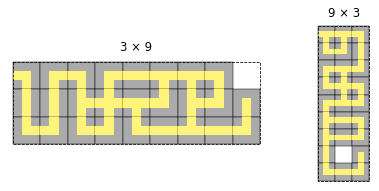

In [ ]:
def mit_neustarts(vorrat, m, n, versuche, grenze):
    """Gibt (Labyrinth oder None, Text, gelegte Würfel insgesamt) zurück."""
    gesamt = 0
    for startzahl in range(versuche):
        stand = labyrinthe(vorrat, m, n, 1, startzahl, grenze)
        gesamt += stand['gelegt']
        if stand['loesungen']:
            return stand['loesungen'][0], f'gefunden mit Startzahl {startzahl}', gesamt
        if not stand['abgebrochen']:
            return None, 'keines möglich', gesamt
    return None, f'nach {versuche} Versuchen nichts gefunden', gesamt


def kool(vorrat, mehr=4, versuche=20, grenze=5000, ausgabe=True):
    """Kool-Labyrinthe mit kleinster Fläche: Liste von Brettern (leer, wenn nichts gefunden)."""
    if eingang_von(vorrat) is None:
        if ausgabe:
            print('Kein Eingang links oben möglich: Die Kontakte passen nicht zusammen.')
        return []
    gefunden = []
    for m, n in brettgroessen(vorrat, mehr):
        if gefunden and m * n > len(gefunden[0]) * len(gefunden[0][0]):
            break                                          # größere Fläche: nicht mehr nötig
        brett, text, gelegt = mit_neustarts(vorrat, m, n, versuche, grenze)
        if ausgabe:
            print(f'{m:2} × {n:<2}  {text:34} {gelegt:6} gelegt')
        if brett is not None:
            gefunden.append(brett)
    return gefunden


AUFGABE_KLEIN = kool(AUFGABE)
fig, axs = plt.subplots(1, 2, figsize=(7, 3), gridspec_kw={'width_ratios': [9, 3]})
for i in range(2):
    print(zeige(AUFGABE_KLEIN[i]), pruefe(AUFGABE_KLEIN[i], AUFGABE), '\n')
    zeichne(AUFGABE_KLEIN[i], axs[i], f'{len(AUFGABE_KLEIN[i])} × {len(AUFGABE_KLEIN[i][0])}')
plt.show()

Mit Neustarts findet die Suche auch 9 × 3 schnell. Weil die Raumecke rechts unten liegt, kann der Kindergarten wählen, ob das
Labyrinth an der langen Wand liegen soll (3 × 9) oder an der anderen (9 × 3).

**Mehrere Lösungen.** Die Aufgabe verlangt, dass das Programm Labyrinthe (Mehrzahl) ausgibt. Mit verschiedenen Startzahlen bekommen
wir verschiedene Labyrinthe; wer es lieber quadratischer mag, nimmt eines der Bretter 5 × 6 oder 6 × 5 wie im Aufgabenblatt. Mit
`wie_viele` liefert die Tiefensuche auch mehrere Labyrinthe hintereinander, die unterscheiden sich aber oft nur am Ende.

3 × 9, Startzahl 5: 11869 gelegt, Fehler: []
3 × 9, Startzahl 7: 20940 gelegt, Fehler: []
5 × 6, Startzahl 1: 888 gelegt, Fehler: []
6 × 5, Startzahl 2: 466 gelegt, Fehler: []


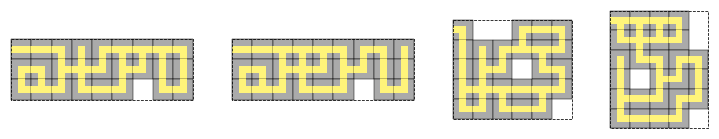

In [ ]:
VIELE = []
for m, n, startzahl in [(3, 9, 5), (3, 9, 7), (5, 6, 1), (6, 5, 2)]:
    stand = labyrinthe(AUFGABE, m, n, 1, startzahl)
    VIELE.append(stand['loesungen'][0])
    print(f"{m} × {n}, Startzahl {startzahl}: {stand['gelegt']} gelegt, Fehler: {pruefe(VIELE[-1], AUFGABE)}")

fig, axs = plt.subplots(1, 4, figsize=(13, 3), gridspec_kw={'width_ratios': [9, 9, 6, 5]})
for i in range(4):
    zeichne(VIELE[i], axs[i])
plt.show()

## Schritt 8: Größere Würfelmengen

Die Aufgabe sagt, dass andere Kindergärten „potenziell deutlich größere Würfelmengen“ haben. Um Würfelmengen zu bekommen, für die es
sicher ein Labyrinth gibt, bauen wir zufällige Labyrinthe und schauen nur, welche Würfel darin vorkommen:

1. Auf einem Brett m × n entfernen wir `luecken` zufällige Felder (nicht das Eingangsfeld), aber nur, wenn die übrigen Felder
   zusammenhängend bleiben und die letzte Zeile und Spalte belegt bleiben.
2. Wie beim Algorithmus von Prim wächst vom Eingangsfeld aus ein zufälliger Baum: Wir wählen immer wieder eine zufällige Kante von
   einem Feld im Baum zu einem Feld außerhalb und öffnen sie. So entsteht ein Labyrinth ohne Kreise.
3. Jede weitere Kante zwischen zwei belegten Feldern öffnen wir mit der Wahrscheinlichkeit `kreise`. Dann gibt es auch Rundgänge
   wie im Beispiel aus dem Aufgabenblatt.

`durcheinander` schreibt die Würfel eines Bretts gemischt in Zeilen zu je 16 Zeichen – so stehen sie in den Dateien, damit man die
Lösung nicht sieht.

In [ ]:
def zusammenhaengend(felder):
    start = min(felder)
    gesehen = {start}
    stapel = [start]
    while stapel:
        r, c = stapel.pop()
        for d in 'LROU':
            nachbar = (r + SCHRITT[d][0], c + SCHRITT[d][1])
            if nachbar in felder and nachbar not in gesehen:
                gesehen.add(nachbar)
                stapel.append(nachbar)
    return len(gesehen) == len(felder)


def zufallslabyrinth(m, n, luecken, kreise, startzahl):
    zufall = random.Random(startzahl)
    felder = set()
    for r in range(m):
        for c in range(n):
            felder.add((r, c))
    kandidaten = sorted(felder - {(0, 0)})
    zufall.shuffle(kandidaten)
    entfernt = 0
    for feld in kandidaten:                                # 1. Lücken
        if entfernt == luecken:
            break
        felder.remove(feld)
        rand_ok = any(r == m - 1 for r, c in felder) and any(c == n - 1 for r, c in felder)
        if zusammenhaengend(felder) and rand_ok:
            entfernt += 1
        else:
            felder.add(feld)                               # doch nicht entfernen
    brett = [[''] * n for _ in range(m)]
    offen = {}                                             # Feld -> Menge der offenen Seiten
    for feld in felder:
        offen[feld] = set()
    offen[(0, 0)].add('L')                                 # der Eingang
    im_baum = {(0, 0)}
    while len(im_baum) < len(felder):                      # 2. zufälliger Baum (Prim)
        rand = []
        for r, c in sorted(im_baum):
            for d in 'LROU':
                nachbar = (r + SCHRITT[d][0], c + SCHRITT[d][1])
                if nachbar in felder and nachbar not in im_baum:
                    rand.append(((r, c), d, nachbar))
        feld, d, nachbar = zufall.choice(rand)
        offen[feld].add(d)
        offen[nachbar].add(GEGEN[d])
        im_baum.add(nachbar)
    for r, c in sorted(felder):                            # 3. ein paar Kreise
        for d in 'RU':
            nachbar = (r + SCHRITT[d][0], c + SCHRITT[d][1])
            if nachbar in felder and d not in offen[(r, c)] and zufall.random() < kreise:
                offen[(r, c)].add(d)
                offen[nachbar].add(GEGEN[d])
    for r, c in felder:
        for d in 'LROU':                                   # als String in der Reihenfolge L, R, O, U
            if d in offen[(r, c)]:
                brett[r][c] += d
    return brett


def durcheinander(brett, startzahl):
    zeichen = []
    for zeile in brett:
        for w in zeile:
            if w != '':
                zeichen.append(ZEICHEN[w])
    random.Random(startzahl).shuffle(zeichen)
    zeilen = []
    for i in range(0, len(zeichen), 16):
        zeilen.append(''.join(zeichen[i:i + 16]))
    return '\n'.join(zeilen)


beispiel = zufallslabyrinth(5, 7, 3, 0.1, 1)
print(zeige(beispiel))
print('Fehler:', pruefe(beispiel, vorrat_von(beispiel)))
print()
print(durcheinander(beispiel, 1))

┬┬╴·╶─┐
│╵╷╷·╶┤
├┐├┘╷·│
│├┼─┴┬┘
╵└┴──┴╴
Fehler: []

└│┤╶─┬┐─╵╷╷├┴┐┴┬
──│├┼┬├┘╶╴╴┘╵┴│╷


Die beiden großen Würfelmengen in `eigene_testdaten/` haben wir genau so erzeugt: `zufall_8x8.txt` mit
`zufallslabyrinth(8, 8, 0, 0.1, 3)` (ein volles Brett, 64 Würfel) und `zufall_10x10.txt` mit `zufallslabyrinth(10, 10, 8, 0.1, 4)`
(92 Würfel). Zur Probe vergleichen wir:

In [ ]:
GROSS = {}
GROESSE = {'zufall_8x8': (8, 8), 'zufall_10x10': (10, 10)}
for name, m, n, luecken, startzahl in [('zufall_8x8', 8, 8, 0, 3), ('zufall_10x10', 10, 10, 8, 4)]:
    GROSS[name] = lies_vorrat(f'eigene_testdaten/{name}.txt')
    gleich = GROSS[name] == vorrat_von(zufallslabyrinth(m, n, luecken, 0.1, startzahl))
    print(f'{name}: {als_text(GROSS[name])}, gleich: {gleich}')

zufall_8x8: ─ 11  │ 3  ┐ 2  └ 7  ┌ 2  ┘ 2  ┤ 4  ┴ 4  ├ 4  ┬ 9  ┼ 2  ╴ 9  ╵ 1  ╶ 3  ╷ 1  (64 Würfel), gleich: True
zufall_10x10: ─ 10  │ 11  ┐ 7  └ 6  ┌ 6  ┘ 3  ┤ 3  ┴ 6  ├ 6  ┬ 5  ┼ 4  ╴ 7  ╵ 10  ╶ 1  ╷ 7  (92 Würfel), gleich: True


Für diese Würfelmengen wissen wir, dass es auf den Brettern 8 × 8 und 10 × 10 ein Labyrinth gibt. Wie schlägt sich die Tiefensuche?
Wir geben ihr 20 000 gelegte Würfel, einmal ohne und einmal mit Neustarts (10 Versuche mit je 2000):

In [ ]:
GROSS_TS = {}
for name in GROSS:
    m, n = GROESSE[name]
    stand = labyrinthe(GROSS[name], m, n, grenze=20000)
    brett, text, gelegt = mit_neustarts(GROSS[name], m, n, 10, 2000)
    GROSS_TS[name] = (ergebnis_text(stand), text, gelegt)
    print(f"{name:13} ohne Neustarts: {ergebnis_text(stand)} ({stand['gelegt']} gelegt)")
    print(f"{'':13} mit Neustarts:  {text} ({gelegt} gelegt)")

zufall_8x8    ohne Neustarts: Grenze erreicht (20086 gelegt)
              mit Neustarts:  nach 10 Versuchen nichts gefunden (20869 gelegt)
zufall_10x10  ohne Neustarts: gefunden (3065 gelegt)
              mit Neustarts:  nach 10 Versuchen nichts gefunden (21483 gelegt)


Beim vollen Brett 8 × 8 findet die Tiefensuche nichts, weder mit noch ohne Neustarts. Auch außerhalb des Notebooks hatte sie keinen
Erfolg, weder mit 300 000 gelegten Würfeln ohne Neustarts noch mit 60 Neustarts zu je 20 000. Bei `zufall_10x10` (mit acht freien
Feldern) hat die alphabetische Reihenfolge Glück und ist nach 3 065 gelegten Würfeln fertig. Mit Neustarts zu je 2000 klappt es dagegen nicht, mit je 5000 erst bei Startzahl 7
(außerhalb gemessen). Ein volles Brett ist besonders schwer: Jedes Feld muss belegt werden, und unser Abbruchkriterium `platz` hilft
kaum, weil kein Feld frei bleiben darf. Bei mehr Würfeln wird es schnell hoffnungslos, denn die Zahl der Möglichkeiten wächst gewaltig – die Lösungshinweise sagen genau das.

## Schritt 9: Simulierte Abkühlung

Die Lösungshinweise empfehlen für große Würfelmengen ein ganz anderes Verfahren. Wir legen **alle** Würfel sofort zufällig auf das
Brett (die übrigen Felder bleiben frei) und zählen die **Fehler**:
- jede falsche Kante (nur eine Seite offen, auch am Rand), wie in `falsche_kanten`,
- jeden Würfel, der vom Eingang aus nicht erreichbar ist.

Dann vertauschen wir immer wieder den Inhalt zweier zufälliger Felder (ein freies Feld zählt wie ein Würfel ohne Kontakte). Wird
die Fehlerzahl dadurch kleiner oder bleibt gleich, behalten wir den Tausch. Wird sie größer, behalten wir ihn trotzdem manchmal,
und zwar mit der Wahrscheinlichkeit e<sup>−Δ/T</sup>; Δ ist die Zunahme der Fehler, T die **Temperatur**. Am Anfang ist T groß, dann
werden auch schlechtere Tausche oft angenommen und die Suche kommt aus Sackgassen heraus. T sinkt langsam („Abkühlung“), am Ende
werden fast nur noch Verbesserungen angenommen. Bei 0 Fehlern haben wir ein Labyrinth.

Zwei Tricks machen das schnell:
- Nach einem Tausch ändern sich nur die Kanten rund um die beiden Felder. `fehler_um` zählt nur diese (jede Kante einmal, auch
  wenn die Felder Nachbarn sind).
- Die Prüfung des Zusammenhangs ist teuer. Statt erst zu rechnen und dann zu würfeln, würfeln wir zuerst eine Zufallszahl u und
  berechnen die **Schranke** `kosten − T · ln(u)`; der Tausch wird genau dann angenommen, wenn die neuen Kosten höchstens so groß
  sind (das ist dasselbe wie „mit Wahrscheinlichkeit e<sup>−Δ/T</sup>“). Liegen schon die falschen Kanten allein über der Schranke,
  sparen wir uns die Prüfung des Zusammenhangs. Das kommt bei niedriger Temperatur sehr oft vor.

In [ ]:
def fehler_um(brett, felder, eingang):
    """Anzahl der falschen Kanten rund um die angegebenen Felder (jede Kante nur einmal)."""
    kanten = set()
    for r, c in felder:
        kanten.add((r, c, 'R'))                     # rechts
        kanten.add((r, c, 'U'))                     # unten
        kanten.add((r, c - 1, 'R'))                 # links = rechts vom linken Nachbarn
        kanten.add((r - 1, c, 'U'))                 # oben = unten vom oberen Nachbarn
    anzahl = 0
    for r, c, d in kanten:
        r2, c2 = r + SCHRITT[d][0], c + SCHRITT[d][1]
        if kontakt(brett, r, c, d, eingang) != kontakt(brett, r2, c2, GEGEN[d], eingang):
            anzahl += 1
    return anzahl


def zuschneiden(brett):
    """Leere Zeilen unten und leere Spalten rechts entfernen."""
    brett = [zeile[:] for zeile in brett]
    while all(w == '' for w in brett[-1]):
        brett.pop()
    while all(zeile[-1] == '' for zeile in brett):
        for zeile in brett:
            zeile.pop()
    return brett


def abkuehlen(vorrat, m, n, startzahl, schritte=100000, t_start=1.0, t_ende=0.05):
    """Simulierte Abkühlung auf einem Brett m x n. Gibt (Labyrinth oder None, Zähler) zurück."""
    zufall = random.Random(startzahl)
    eingang = eingang_von(vorrat)
    k = sum(vorrat.values())
    inhalt = []
    for w in vorrat:
        inhalt += [w] * vorrat[w]
    inhalt += [''] * (m * n - k)                   # freie Felder
    zufall.shuffle(inhalt)
    brett = []
    for r in range(m):
        brett.append(inhalt[r * n:(r + 1) * n])
    falsch = len(falsche_kanten(brett, eingang))
    kosten = falsch + k - len(erreichbar(brett))
    felder = []
    for r in range(m):
        for c in range(n):
            felder.append((r, c))
    zaehler = {'tausche': 0, 'zusammenhang': 0, 'fehler': kosten}
    for schritt in range(schritte):
        if kosten == 0:
            break
        temperatur = t_start * (t_ende / t_start) ** (schritt / schritte)   # sinkt von t_start bis t_ende
        (r1, c1), (r2, c2) = zufall.sample(felder, 2)
        if brett[r1][c1] == brett[r2][c2]:
            continue                                # gleiche Würfel zu tauschen bringt nichts
        zaehler['tausche'] += 1
        vorher = fehler_um(brett, [(r1, c1), (r2, c2)], eingang)
        brett[r1][c1], brett[r2][c2] = brett[r2][c2], brett[r1][c1]
        falsch_neu = falsch - vorher + fehler_um(brett, [(r1, c1), (r2, c2)], eingang)
        schranke = kosten - temperatur * math.log(1 - zufall.random())      # 1 - random() liegt in (0, 1]
        angenommen = False
        if falsch_neu <= schranke:
            zaehler['zusammenhang'] += 1
            kosten_neu = falsch_neu + k - len(erreichbar(brett))
            if kosten_neu <= schranke:
                angenommen = True
                falsch, kosten = falsch_neu, kosten_neu
        if not angenommen:
            brett[r1][c1], brett[r2][c2] = brett[r2][c2], brett[r1][c1]     # zurücktauschen
    zaehler['fehler'] = kosten
    if kosten == 0:
        return zuschneiden(brett), zaehler
    return None, zaehler


SA = {}
for name in GROSS:
    m, n = GROESSE[name]
    brett, zaehler = abkuehlen(GROSS[name], m, n, 0)
    SA[name] = (brett, zaehler)
    print(name, zaehler, 'Fehler:', pruefe(brett, GROSS[name]) if brett else '-')

zufall_8x8 {'tausche': 32404, 'zusammenhang': 13498, 'fehler': 0} Fehler: []
zufall_10x10 {'tausche': 51462, 'zusammenhang': 23646, 'fehler': 0} Fehler: []


Beide großen Würfelmengen sind nach 32 404 bzw. 51 462 Tauschen fehlerfrei, und `pruefe` bestätigt die Labyrinthe. Den Zusammenhang mussten wir dabei nur
13 498 bzw. 23 646 Mal prüfen.

Ganz sicher ist der Erfolg aber nicht. Außerhalb des Notebooks haben wir die Startzahlen 0 bis 7 probiert: Mit 100 000 Schritten
fand die Abkühlung für `zufall_8x8` bei 7 von 8 Startzahlen ein Labyrinth, für `zufall_10x10` bei 5 von 8; die übrigen blieben mit
2 Fehlern stecken. Mit 200 000 Schritten waren es 8 bzw. 6 von 8. Findet sie nichts, nimmt man eben die nächste Startzahl. Bei einer
Würfelmenge aus `zufallslabyrinth(15, 15, 15, 0.1, 5)` (210 Würfel) blieb sie dagegen auch mit 300 000 Schritten bei allen drei
probierten Startzahlen mit 2 Fehlern stecken.

┬┬─┐╶─┬╴
├┴┬┴──┴╴
└╴├┬───┐
┌╴└┼╴╷┌┤
├┬╴╵╶┴┤│
│└┬┬─┬┼┤
├─┤└╴└┘│
└╴└╴╶──┘


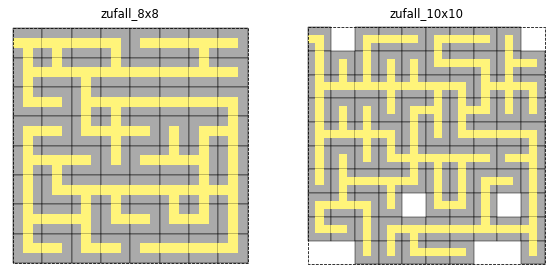

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
for i, name in enumerate(SA):
    zeichne(SA[name][0], axs[i], name)
plt.show()
print(zeige(SA['zufall_8x8'][0]))

Und die Würfel aus dem Aufgabenblatt? Auf dem knappen Brett 3 × 9 (nur ein freies Feld) und auf 5 × 6:

In [ ]:
SA_AUFGABE = {}
for m, n in [(3, 9), (5, 6)]:
    for startzahl in range(3):
        brett, zaehler = abkuehlen(AUFGABE, m, n, startzahl)
        SA_AUFGABE[(m, n, startzahl)] = (brett is not None, zaehler['tausche'])
        print(f'{m} × {n}, Startzahl {startzahl}:', zaehler, 'gefunden' if brett else 'nicht gefunden')

3 × 9, Startzahl 0: {'tausche': 20832, 'zusammenhang': 3337, 'fehler': 0} gefunden
3 × 9, Startzahl 1: {'tausche': 45576, 'zusammenhang': 4374, 'fehler': 0} gefunden
3 × 9, Startzahl 2: {'tausche': 14013, 'zusammenhang': 2798, 'fehler': 0} gefunden
5 × 6, Startzahl 0: {'tausche': 34449, 'zusammenhang': 5450, 'fehler': 0} gefunden
5 × 6, Startzahl 1: {'tausche': 41717, 'zusammenhang': 6448, 'fehler': 0} gefunden
5 × 6, Startzahl 2: {'tausche': 25622, 'zusammenhang': 3334, 'fehler': 0} gefunden


Auch für die Würfel aus dem Aufgabenblatt klappt es, auf dem knappen Brett 3 × 9 und auf 5 × 6 mit allen drei Startzahlen, nach
14 013 bis 45 576 Tauschen.

Die simulierte Abkühlung hat also Vor- und Nachteile, die auch die Lösungshinweise nennen:
- Sie findet für große Würfelmengen schnell Labyrinthe, wo die Tiefensuche keine Chance hat, und mit anderen Startzahlen auch
  andere Labyrinthe.
- Sie kann nie beweisen, dass es auf einem Brett **kein** Labyrinth gibt. Findet sie nichts, wissen wir nichts.
- Der Erfolg hängt von den Parametern ab (Anzahl der Schritte, Anfangs- und Endtemperatur). Unsere Werte haben wir durch Probieren
  gefunden.

## Alle Beispiele

Die Würfel aus dem Aufgabenblatt und die beiden großen Würfelmengen hatten wir schon. Für die übrigen eigenen Würfelmengen sucht
`kool` die kleinste Fläche.

In [ ]:
ALLE = {}
for name in ['ein_wuerfel', 'kamm', 'gitter', 'kein_eingang', 'unmoeglich']:
    vorrat = lies_vorrat(f'eigene_testdaten/{name}.txt')
    print(f'--- {name}: {als_text(vorrat)}, Eingang: {eingang_von(vorrat)}')
    ALLE[name] = kool(vorrat)
    for brett in ALLE[name]:
        print(zeige(brett))
        print('Fehler:', pruefe(brett, vorrat))

--- ein_wuerfel: ╴ 1  (1 Würfel), Eingang: L
 1 × 1   gefunden mit Startzahl 0                1 gelegt
╴
Fehler: []
--- kamm: ─ 1  ┐ 1  ┬ 3  ╵ 4  (9 Würfel), Eingang: L
 1 × 9   keines möglich                          1 gelegt
 3 × 3   keines möglich                         20 gelegt
 9 × 1   keines möglich                          2 gelegt
 1 × 10  keines möglich                          1 gelegt
 2 × 5   gefunden mit Startzahl 0               18 gelegt
 5 × 2   keines möglich                          9 gelegt
10 × 1   keines möglich                          2 gelegt
─┬┬┬┐
·╵╵╵╵
Fehler: []
--- gitter: ┐ 1  └ 1  ┘ 1  ┤ 1  ┴ 1  ├ 1  ┬ 2  ┼ 1  (9 Würfel), Eingang: L
 3 × 3   gefunden mit Startzahl 0               13 gelegt
┬┬┐
├┼┤
└┴┘
Fehler: []
--- kein_eingang: ┐ 1  └ 1  ┌ 1  ┘ 1  (4 Würfel), Eingang: None
Kein Eingang links oben möglich: Die Kontakte passen nicht zusammen.
--- unmoeglich: ╴ 1  ╵ 1  ╷ 1  (3 Würfel), Eingang: L
 1 × 3   keines möglich                          1 gelegt
 

- `ein_wuerfel`: der kleinste Fall, ein Brett 1 × 1 mit dem Eingang als Sackgasse.
- `kamm`: Für die Bretter mit 9 Feldern beweist die Suche, dass es nicht geht (alles durchprobiert, ohne die Grenze zu erreichen).
  Das kleinste Brett ist 2 × 5 mit einem freien Feld.
- `gitter`: Hier gibt es nur das Gitter selbst auf 3 × 3.
- `kein_eingang`: Die Zählung schließt den Ring sofort aus.
- `unmoeglich`: Die Zählung passt (ein L-Kontakt mehr als R-Kontakte, gleich viele O- und U-Kontakte), trotzdem gibt es kein
  Labyrinth: Der Eingangswürfel muss links offen und oben geschlossen sein, das ist nur `╴`, und der schließt das Labyrinth sofort
  ab. Die Suche beweist das für jedes Brett einzeln, hier für alle bis zur Fläche 7.

## Für Neugierige

**Die Markierung muss nicht nach oben zeigen.** Die Aufgabe verlangt nur, dass alle Markierungen in die *gleiche* Richtung zeigen.
Zeigen alle nach rechts, ist jeder Würfel gegenüber unserem Bild um 90° im Uhrzeigersinn gedreht: Aus einem Kontakt links wird einer
oben, aus oben wird rechts, aus rechts unten und aus unten links. `drehe` dreht einen ganzen Vorrat so. Bei den Würfeln aus dem
Aufgabenblatt zeigt der Eingang danach nach oben, und es gibt wieder Labyrinthe. Bei 180° und 270° zeigt der überzählige Kontakt
nach rechts bzw. unten, dann kann der Eingang nicht links oben liegen.

In [ ]:
DREHUNG = {'L': 'O', 'O': 'R', 'R': 'U', 'U': 'L'}       # 90° im Uhrzeigersinn


def drehe(vorrat):
    neu = {}
    for w in vorrat:
        gedreht = ''
        for d in 'LROU':                                 # in der festen Reihenfolge L, R, O, U zusammensetzen
            for alt in w:
                if DREHUNG[alt] == d:
                    gedreht += d
        neu[gedreht] = vorrat[w]
    return neu


v = AUFGABE
for grad in [0, 90, 180, 270]:
    print(f'{grad:3}°: {als_text(v)}  Eingang: {eingang_von(v)}')
    v = drehe(v)
GEDREHT = kool(drehe(AUFGABE), versuche=5)
print(zeige(GEDREHT[0]))

  0°: ─ 3  │ 2  ┐ 3  └ 3  ┌ 2  ┘ 5  ┴ 1  ├ 2  ┬ 3  ┼ 1  ╷ 1  (26 Würfel)  Eingang: L
 90°: ─ 2  │ 3  ┐ 2  └ 5  ┌ 3  ┘ 3  ┤ 3  ├ 1  ┬ 2  ┼ 1  ╴ 1  (26 Würfel)  Eingang: O
180°: ─ 3  │ 2  ┐ 3  └ 3  ┌ 5  ┘ 2  ┤ 2  ┴ 3  ┬ 1  ┼ 1  ╵ 1  (26 Würfel)  Eingang: None
270°: ─ 2  │ 3  ┐ 5  └ 2  ┌ 3  ┘ 3  ┤ 1  ┴ 2  ├ 3  ┼ 1  ╶ 1  (26 Würfel)  Eingang: None
 3 × 9   nach 5 Versuchen nichts gefunden    25101 gelegt
 9 × 3   gefunden mit Startzahl 0             1483 gelegt
└┬╴
·└┐
┌┬┘
└┼┐
┌┘│
├─┤
│┌┤
│└┤
└─┘


Das ist der Grundriss im Raum: Die Markierungen zeigen alle nach rechts, der Eingang liegt links oben und zeigt nach oben. Auf
9 × 3 gibt es also auch mit gedrehten Würfeln ein Labyrinth, auf 3 × 9 hat die Suche in fünf Versuchen keines gefunden. Dort gibt es
auch keines: Eine Tiefensuche ohne Grenze hat außerhalb des Notebooks alles durchprobiert (414 567 gelegte Würfel), und MiniZinc
bestätigt das am Ende des Notebooks.

**Wie viele Labyrinthe gibt es?** Lässt man die Tiefensuche ohne Grenze und mit beliebig großem `wie_viele` laufen, findet sie jedes
Labyrinth genau einmal (in jedem Schritt ist das Feld eindeutig festgelegt, nur der Würfel wird probiert). Außerhalb des Notebooks
haben wir so gezählt: Mit den Würfeln aus dem Aufgabenblatt gibt es auf 3 × 9 genau 4072 Labyrinthe, auf 9 × 3 genau 285.
Für das kleine Gitter geht das auch hier:

In [ ]:
GITTER = lies_vorrat('eigene_testdaten/gitter.txt')
for m, n in [(3, 3), (3, 4), (4, 3)]:
    stand = labyrinthe(GITTER, m, n, wie_viele=1000)
    print(f"{m} × {n}: {len(stand['loesungen'])} Labyrinthe, {stand['gelegt']} gelegt")

3 × 3: 1 Labyrinthe, 59 gelegt
3 × 4: 0 Labyrinthe, 93 gelegt
4 × 3: 0 Labyrinthe, 80 gelegt


Auf 3 × 4 und 4 × 3 gibt es keines, die Suche hat dort alles durchprobiert.

**Abbruchkriterien.** Unser Kriterium `platz` (genug freie Felder für die übrigen Würfel) ist sehr wirksam: Ohne es braucht die
Suche für 3 × 9 77 503 statt 22 076 gelegte Würfel und für 9 × 3 749 465 statt 207 535 (außerhalb gemessen). Die
Lösungshinweise schlagen außerdem vor abzubrechen, wenn in einer Richtung mehr offene Kontakte auf dem Brett zeigen, als der Vorrat
passende Würfel hat (z. B. drei offene Felder, die einen L-Kontakt brauchen, aber nur noch zwei Würfel mit L-Kontakt). Das haben wir
außerhalb des Notebooks ausprobiert: Bei 3 × 9 schlägt es 14-mal an, bei 9 × 3 33-mal, aber die Zahl der gelegten Würfel bleibt
genau gleich. In diesen Stellungen ging es auch so nicht mehr weiter.

**Weitere Ideen aus den Lösungshinweisen:** Gibt es einen kleinen abgeschlossenen Bereich mit einem offenen Feld, kann man ihn zuerst
füllen. Bei der simulierten Abkühlung kann man die Randfelder gleich so belegen, dass kein Kontakt nach außen zeigt. Und man kann die
Aufgabe erweitern: sechseckige Würfel in einem Wabenraster oder ein Labyrinth, das in ein Dreieck in der Raumecke passt.

## Zum Schluss: Kool-Labyrinthe mit MiniZinc

Kool passt gut zu MiniZinc: Für jedes Feld gibt es ein paar Entscheidungen (welche Seiten offen sind), dazu kommen Bedingungen
zwischen Nachbarfeldern und eine Zählbedingung für den Vorrat. Wir modellieren die Kontakte mit vier `bool`-Arrays `L`, `R`, `O`, `U`.
Die Sorte eines Feldes ist dann eine Zahl von 0 bis 15, genau wie die Bitdarstellung in den Lösungshinweisen:
`sorte = 8*L + 4*R + 2*O + U` (ein `bool` zählt dabei als 0 oder 1), 0 ist ein freies Feld.

- **Kontakte:** `R[i,j] = L[i,j+1]` und `U[i,j] = O[i+1,j]`, am Rand ist alles zu, außer dem Eingang am Feld (1, 1).
- **Vorrat:** `global_cardinality` sorgt dafür, dass jede Sorte 1 bis 15 genau `anzahl[s]`-mal vorkommt (wie oft 0 vorkommt, ist frei).
- **Rechteck:** `exists` ist das Gegenstück zu `forall`: Mindestens ein Feld der letzten Zeile bzw. Spalte ist belegt.
- **Zusammenhang:** Das ist der schwierige Teil, denn „erreichbar“ lässt sich nicht direkt hinschreiben. Wir benutzen einen
  **Fluss**: Durch den Eingang fließen k Einheiten (z. B. Liter Wasser) hinein, jeder Würfel behält genau eine, und fließen kann es
  nur durch offene Kanten. `nach_rechts[i,j]` ist, was vom Feld (i, j) zum rechten Nachbarn fließt; ein negativer Wert heißt, dass es
  von rechts kommt. Für jedes Feld gilt: Was hineinfließt, minus was hinausfließt, ist 1 bei einem Würfel und 0 bei einem freien Feld.
  Ein Würfel, der vom Eingang aus nicht erreichbar ist, bekäme nichts ab. `bool2int` macht aus `true`/`false` die Zahl 1/0, `abs` ist
  der Betrag. Neu ist auch `if … then … else … endif`; hier hängt die Bedingung nur von festen Zahlen ab (am Rand fehlt ein Nachbar).
- **Ausgabe:** Das Array `Z` übersetzt die Sorten in Kastenzeichen (`Z[s + 1]`, weil Arrays bei 1 beginnen). `fix` braucht man, um
  den Wert einer Variablen in der Ausgabe als Index zu benutzen.

```minizinc
include "globals.mzn";
int: m;                                   % Zeilen
int: n;                                   % Spalten
int: k;                                   % Anzahl der Würfel
array[1..15] of int: anzahl;              % anzahl[s]: so viele Würfel der Sorte s = 8*L + 4*R + 2*O + U
bool: eingang_links;                      % Eingang links (sonst oben) am Feld (1, 1)

/* Kontakte jedes Feldes: links, rechts, oben, unten */
array[1..m, 1..n] of var bool: L;
array[1..m, 1..n] of var bool: R;
array[1..m, 1..n] of var bool: O;
array[1..m, 1..n] of var bool: U;
array[1..m, 1..n] of var 0..15: sorte;    % 0 = freies Feld
constraint forall(i in 1..m, j in 1..n)(sorte[i,j] = 8*L[i,j] + 4*R[i,j] + 2*O[i,j] + U[i,j]);

/* Kontakte passen zusammen, nichts zeigt nach außen, außer dem Eingang */
constraint forall(i in 1..m, j in 1..n-1)(R[i,j] = L[i,j+1]);
constraint forall(i in 1..m-1, j in 1..n)(U[i,j] = O[i+1,j]);
constraint forall(i in 1..m)(not R[i,n]) /\ forall(j in 1..n)(not U[m,j]);
constraint forall(i in 2..m)(not L[i,1]) /\ forall(j in 2..n)(not O[1,j]);
constraint L[1,1] = eingang_links /\ O[1,1] = not eingang_links;

/* genau die Würfel aus dem Vorrat */
constraint global_cardinality([sorte[i,j] | i in 1..m, j in 1..n], [s | s in 1..15], anzahl);

/* das Rechteck umfasst das Labyrinth genau */
constraint exists(j in 1..n)(sorte[m,j] > 0) /\ exists(i in 1..m)(sorte[i,n] > 0);

/* Zusammenhang: k Einheiten fließen durch den Eingang hinein, jeder Würfel behält genau eine */
array[1..m, 1..n] of var -k..k: nach_rechts;   % Fluss zum rechten Nachbarn (negativ: von dort zu uns)
array[1..m, 1..n] of var -k..k: nach_unten;    % Fluss zum unteren Nachbarn
constraint forall(i in 1..m, j in 1..n)(abs(nach_rechts[i,j]) <= k * R[i,j] /\ abs(nach_unten[i,j]) <= k * U[i,j]);
constraint forall(i in 1..m, j in 1..n)(
    (if i == 1 /\ j == 1 then k else 0 endif)                  % durch den Eingang
    + (if j > 1 then nach_rechts[i,j-1] else 0 endif)         % vom linken Nachbarn
    + (if i > 1 then nach_unten[i-1,j] else 0 endif)          % vom oberen Nachbarn
    - nach_rechts[i,j] - nach_unten[i,j]                      % weiter nach rechts und unten
    = bool2int(sorte[i,j] > 0));

solve satisfy;

array[1..16] of string: Z = ["·", "╷", "╵", "│", "╶", "┌", "└", "├", "╴", "┐", "┘", "┤", "─", "┬", "┴", "┼"];
output [Z[fix(sorte[i,j]) + 1] ++ if j == n then "\n" else "" endif | i in 1..m, j in 1..n];
```

Die Datendatei schreibt `als_dzn`:

In [ ]:
def als_dzn(vorrat, m, n):
    anzahl = [0] * 15
    for w in vorrat:
        s = 8 * ('L' in w) + 4 * ('R' in w) + 2 * ('O' in w) + 1 * ('U' in w)
        anzahl[s - 1] = vorrat[w]
    eingang = 'true' if eingang_von(vorrat) == 'L' else 'false'
    return f'm = {m};\nn = {n};\nk = {sum(vorrat.values())};\nanzahl = {anzahl};\neingang_links = {eingang};'


print(als_dzn(AUFGABE, 3, 9))

m = 3;
n = 9;
k = 26;
anzahl = [1, 0, 2, 0, 2, 3, 2, 0, 3, 5, 0, 3, 3, 1, 1];
eingang_links = true;


Ergebnisse (die Würfel aus dem Aufgabenblatt, dieselben gedreht wie bei den Neugierigen, die beiden großen Würfelmengen):

`aufgabe` auf 3 × 9 mit Gecode:

**Ausgabe:**

```
┐╷┌┬┐┌┬┬┐
└┼┘│├┘├┘│
·└─┘└─┴─┘
----------
```

`gedreht` auf 3 × 9 mit Gecode:

**Ausgabe:**

```
=====UNSATISFIABLE=====
```

`zufall_8x8` auf 8 × 8 mit Gecode:

**Ausgabe:**

```
──┬┬┬──╴
╷┌┤└┴┬─╴
└┘└┬┬┼─╴
┌┬╴└┼┴─╴
│└┬┐└┬─╴
│╶┤├┐├─╴
│╶┤├┤├─╴
╵╶┘└┴┴─╴
----------
```

`zufall_10x10` auf 10 × 10 mit Chuffed:

**Ausgabe:**

```
┐╷╷╷╷╷╷┌┬┐
├┴┤├┼┼┘╵│╵
╵╷└┤╵╵┌┬┼╴
╶┼╴│┌┐╵╵├┐
·│┌┤│└─╴│╵
·├┴┴┴──╴│·
·└──┬──╴│·
··┌┐├┬┐·├┐
┌┬┘│╵│└╴││
╵└╴└─┴──┴┘
----------
```

`zufall_10x10` auf 4 × 23 mit Gecode:

**Ausgabe:**

```
┬─┐┌─┐┌─┐┌┬┬─┬──╴╷╷╷╷╷╷
│┌┼┤┌┼┤┌┼┤├┴╴├──┐└┼┘├┴┘
││││││││││└┬╴├─┐└┐├┐├╴╷
╵╵╵╵╵╵╵╵╵╵╶┴╴└╴└╴└┴┴┴─┘
----------
```


`=====UNSATISFIABLE=====` heißt: Der Solver hat bewiesen, dass es kein Labyrinth gibt. Für die gedrehten Würfel auf 3 × 9 bestätigt
das die vollständige Tiefensuche von oben. Die ersten Zeilen der anderen Ausgaben sind Labyrinthe. Wir übertragen sie in Python und
prüfen sie mit `pruefe`:

In [ ]:
MINIZINC = {
    ('aufgabe', 3, 9): '''
┐╷┌┬┐┌┬┬┐
└┼┘│├┘├┘│
·└─┘└─┴─┘''',
    ('zufall_8x8', 8, 8): '''
──┬┬┬──╴
╷┌┤└┴┬─╴
└┘└┬┬┼─╴
┌┬╴└┼┴─╴
│└┬┐└┬─╴
│╶┤├┐├─╴
│╶┤├┤├─╴
╵╶┘└┴┴─╴''',
    ('zufall_10x10', 10, 10): '''
┐╷╷╷╷╷╷┌┬┐
├┴┤├┼┼┘╵│╵
╵╷└┤╵╵┌┬┼╴
╶┼╴│┌┐╵╵├┐
·│┌┤│└─╴│╵
·├┴┴┴──╴│·
·└──┬──╴│·
··┌┐├┬┐·├┐
┌┬┘│╵│└╴││
╵└╴└─┴──┴┘''',
    ('zufall_10x10', 4, 23): '''
┬─┐┌─┐┌─┐┌┬┬─┬──╴╷╷╷╷╷╷
│┌┼┤┌┼┤┌┼┤├┴╴├──┐└┼┘├┴┘
││││││││││└┬╴├─┐└┐├┐├╴╷
╵╵╵╵╵╵╵╵╵╵╶┴╴└╴└╴└┴┴┴─┘''',
}
VORRAT = {'aufgabe': AUFGABE, 'zufall_8x8': GROSS['zufall_8x8'], 'zufall_10x10': GROSS['zufall_10x10']}
for name, m, n in MINIZINC:
    brett = []
    for zeile in MINIZINC[(name, m, n)].strip().split('\n'):
        brett.append([WUERFEL.get(zeichen, '') for zeichen in zeile])
    print(f'{name:13} {m:2} × {n:<2}  Fehler: {pruefe(brett, VORRAT[name])}')

aufgabe        3 × 9   Fehler: []
zufall_8x8     8 × 8   Fehler: []
zufall_10x10  10 × 10  Fehler: []
zufall_10x10   4 × 23  Fehler: []


Bemerkenswert ist das letzte Ergebnis: Die 92 Würfel von `zufall_10x10` passen auf ein Brett 4 × 23 **ohne ein einziges freies
Feld**. Kleiner geht es nicht, also ist das die kleinste Fläche. Mit unserer Tiefensuche hatten wir bei vollen Brettern keinen
Erfolg, und die simulierte Abkühlung haben wir nur auf 10 × 10 laufen lassen.

**Wie schnell sind die Solver?** Außerhalb des Notebooks gemessen, Zeitlimit 60 s (`>60 s` heißt: abgebrochen ohne Ergebnis):

| Würfel | Brett | Gecode | Chuffed | HiGHS |
|---|---|---|---|---|
| aufgabe | 3 × 9 | unter 1 s | unter 1 s | 2 s |
| aufgabe | 9 × 3 | unter 1 s | unter 1 s | 1 s |
| gedreht (kein Labyrinth) | 3 × 9 | unter 1 s | unter 1 s | 4 s |
| zufall_8x8 | 8 × 8 | unter 1 s | 1 s | 23 s |
| zufall_10x10 | 10 × 10 | >60 s | 2 s | >60 s |
| zufall_10x10 | 4 × 23 | unter 1 s | >60 s | >60 s |
| zufall_10x10 | 23 × 4 | >60 s | >60 s | >60 s |
| 210 Würfel aus `zufallslabyrinth(15, 15, 15, 0.1, 5)` | 15 × 15 | unter 1 s | >60 s | >60 s |

Gecode und Chuffed sind oft verblüffend schnell, aber unberechenbar: Derselbe Solver, der 210 Würfel in unter einer Sekunde
unterbringt, findet für 92 Würfel auf 10 × 10 in einer Minute nichts. Bei der Wahl des Solvers lohnt es sich also, mehrere zu
probieren. HiGHS rechnet das Modell als lineares Optimierungsproblem und ist hier deutlich langsamer. Anders als die simulierte
Abkühlung kann MiniZinc auch beweisen, dass es kein Labyrinth gibt – bei kleinen Brettern wie 3 × 9 in Sekundenbruchteilen. Ob
die 92 Würfel auch auf 23 × 4 passen, wissen wir dagegen nicht: Keiner der drei Solver kam in einer Minute zu einem Ergebnis.